In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Customer Churn Prediction project started!")


Customer Churn Prediction project started!


In [2]:
from pathlib import Path

data_path = Path("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Check dataset dimensions and column names
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Number of rows: 7043
Number of columns: 21

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 no

In [4]:
# Check missing values
print("Missing values in each column:")
display(df.isnull().sum().sort_values(ascending=False))

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Check target distribution
print("\nChurn distribution:")
display(df["Churn"].value_counts())

print("\nChurn percentage:")
display(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)

Missing values in each column:


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


Duplicate rows: 0

Churn distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn percentage:


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

In [5]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Missing TotalCharges after conversion:",
      df["TotalCharges"].isna().sum())

display(df[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].head(10))

Missing TotalCharges after conversion: 11


,tenure,MonthlyCharges,TotalCharges,Churn
0,1,29.85,29.85,No
1,34,56.95,1889.50,No
2,2,53.85,108.15,Yes
3,45,42.30,1840.75,No
4,2,70.70,151.65,Yes
5,8,99.65,820.50,Yes
6,22,89.10,1949.40,No
7,10,29.75,301.90,No
8,28,104.80,3046.05,Yes
9,62,56.15,3487.95,No


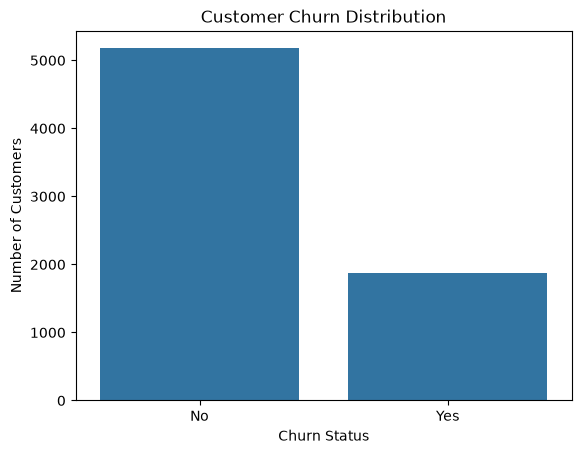

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.show()

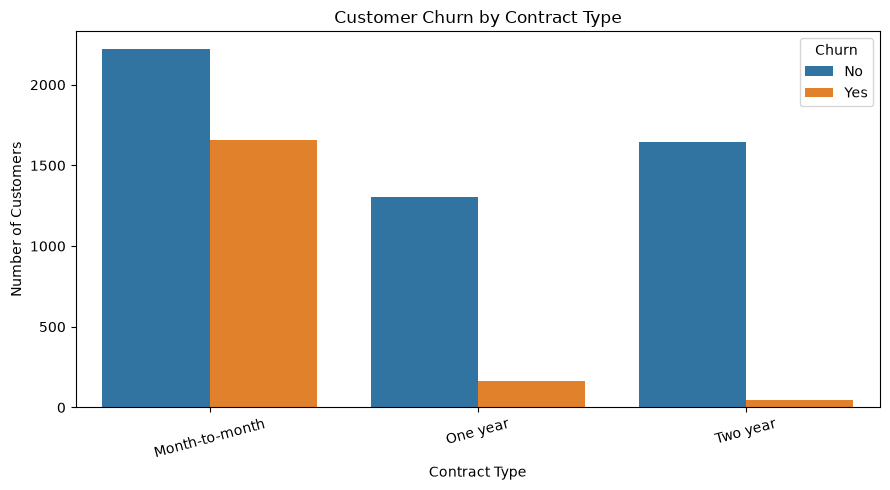

In [7]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

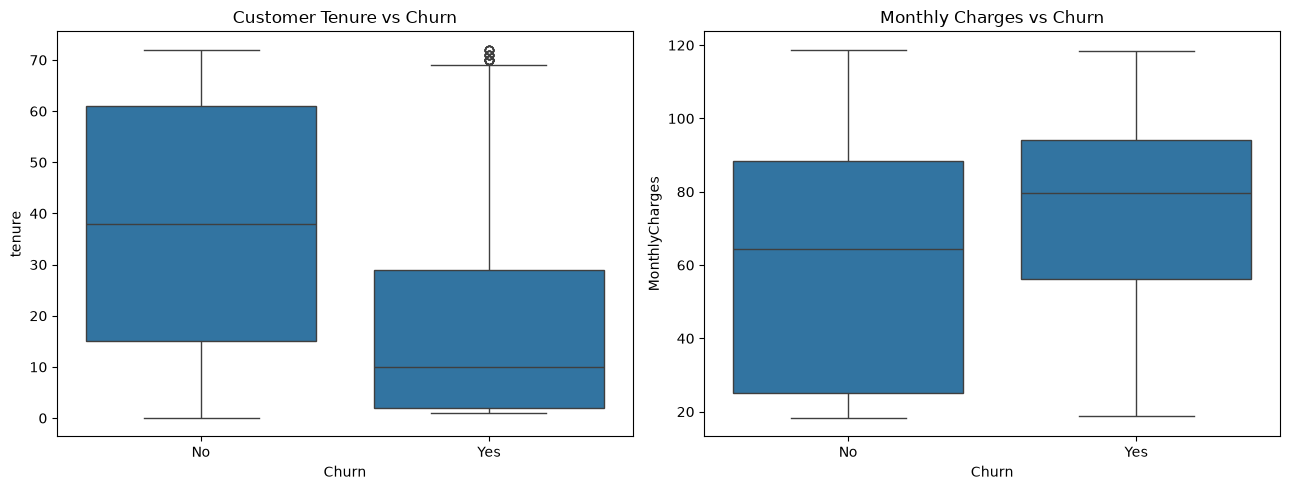

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[0])
axes[0].set_title("Customer Tenure vs Churn")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("Monthly Charges vs Churn")

plt.tight_layout()
plt.show()

In [9]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Convert churn into numbers: No = 0, Yes = 1
y = df["Churn"].map({"No": 0, "Yes": 1})

# Remove target and customer ID from input features
X = df.drop(columns=["Churn", "customerID"])

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Features shape: (7043, 19)
Target shape: (7043,)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


In [10]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\K THARUN\AppData\Local\Temp\ipykernel_20712\1755248518.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 5634
Testing records: 1409


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)
print("Total encoded features:", len(feature_names))

Training data after preprocessing: (5634, 45)
Testing data after preprocessing: (1409, 45)
Total encoded features: 45


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_processed, y_train)
    trained_models[name] = model

print("All three models trained successfully!")

Training Logistic Regression...
Training Random Forest...
Training Gradient Boosting...
All three models trained successfully!


In [14]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, model in trained_models.items():
    probabilities = model.predict_proba(X_test_processed)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results).sort_values(
    "ROC-AUC", ascending=False
)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Gradient Boosting,0.8062,0.6735,0.5241,0.5895,0.8434
0,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8413
1,Random Forest,0.7622,0.5391,0.7193,0.6163,0.8346


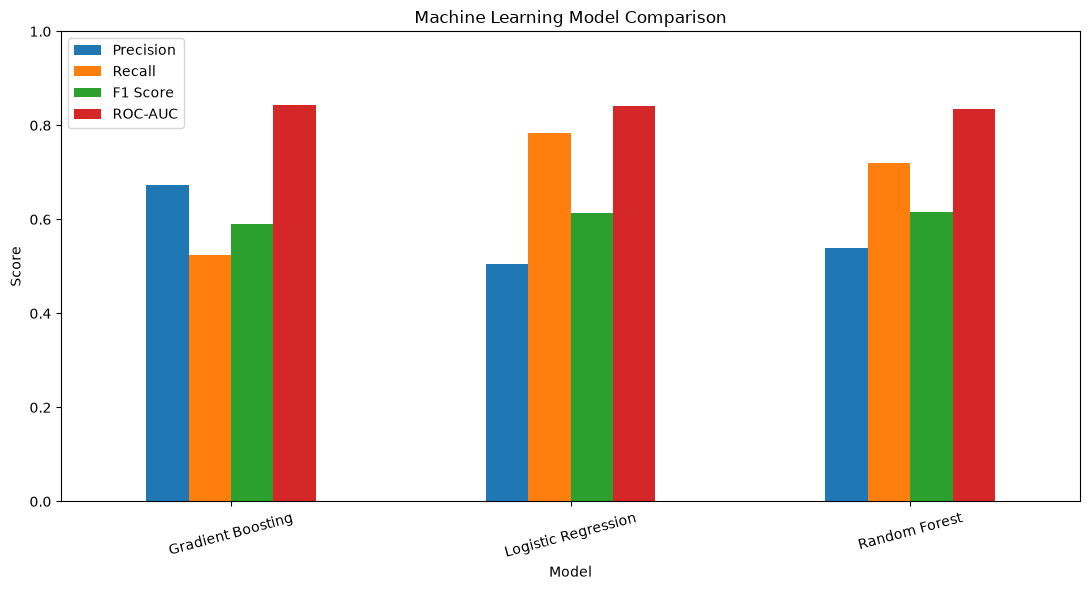

In [15]:
results_df.set_index("Model")[
    ["Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(kind="bar", figsize=(11, 6))

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [16]:
# Select Logistic Regression for initial analysis
best_model_name = "Logistic Regression"
best_model = trained_models[best_model_name]

# Predict churn probabilities
test_probabilities = best_model.predict_proba(
    X_test_processed
)[:, 1]

# Use 0.5 as the initial classification threshold
test_predictions = (test_probabilities >= 0.5).astype(int)

print("Selected model:", best_model_name)

Selected model: Logistic Regression


              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



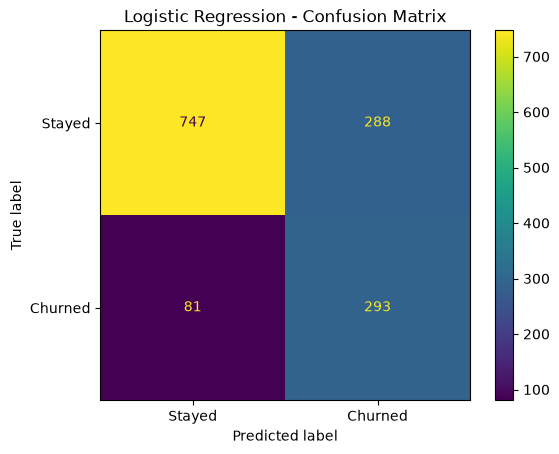

In [17]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

print(classification_report(
    y_test,
    test_predictions,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Stayed", "Churned"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [18]:
import shap
import numpy as np

shap_model = trained_models["Random Forest"]

explainer = shap.TreeExplainer(shap_model)

# Explain a sample of test customers
sample_size = min(300, X_test_processed.shape[0])
X_shap = X_test_processed[:sample_size]

shap_values = explainer(X_shap)

print("SHAP explanations generated successfully!")

SHAP explanations generated successfully!


In [21]:
print("SHAP version:", shap.__version__)
print("SHAP values shape:", shap_values.values.shape)
print("Feature names:", len(feature_names))
print("Input shape:", X_shap.shape)

SHAP version: 0.53.0
SHAP values shape: (300, 45, 2)
Feature names: 45
Input shape: (300, 45)


Selected SHAP shape: (300, 45)


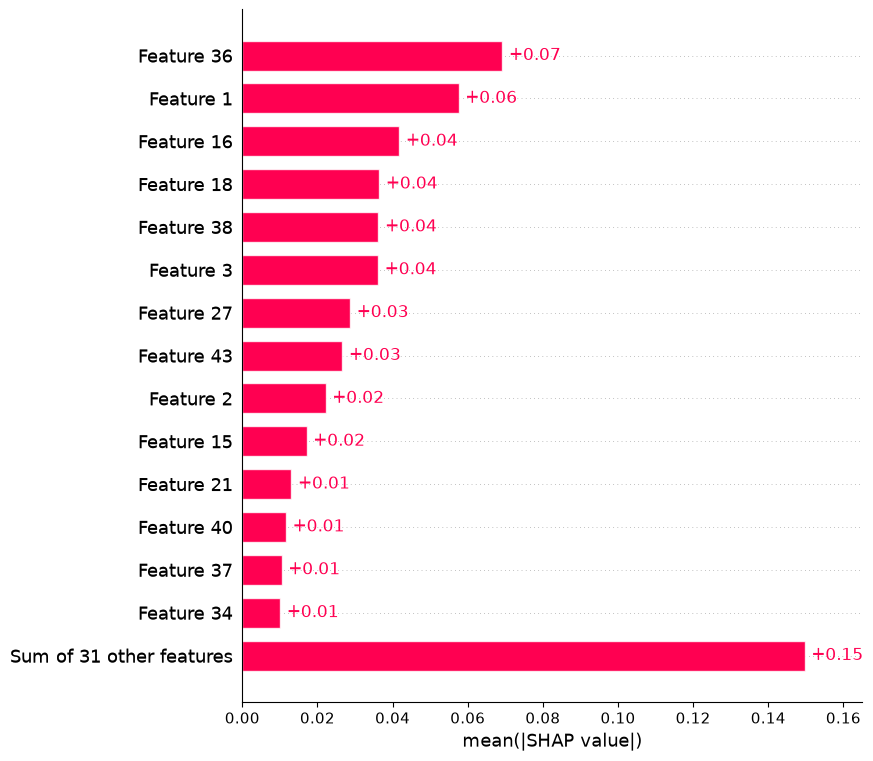

In [22]:
# Select SHAP explanations for the churn class (class 1)
if len(shap_values.values.shape) == 3:
    shap_churn = shap_values[:, :, 1]
else:
    shap_churn = shap_values

print("Selected SHAP shape:", shap_churn.values.shape)

shap.plots.bar(shap_churn, max_display=15)

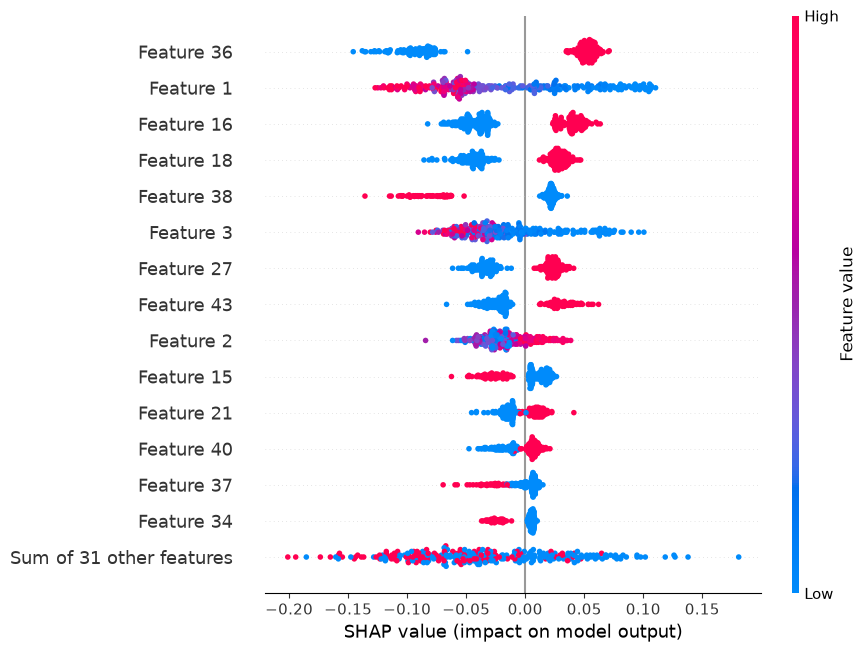

In [23]:
shap.plots.beeswarm(shap_churn, max_display=15)

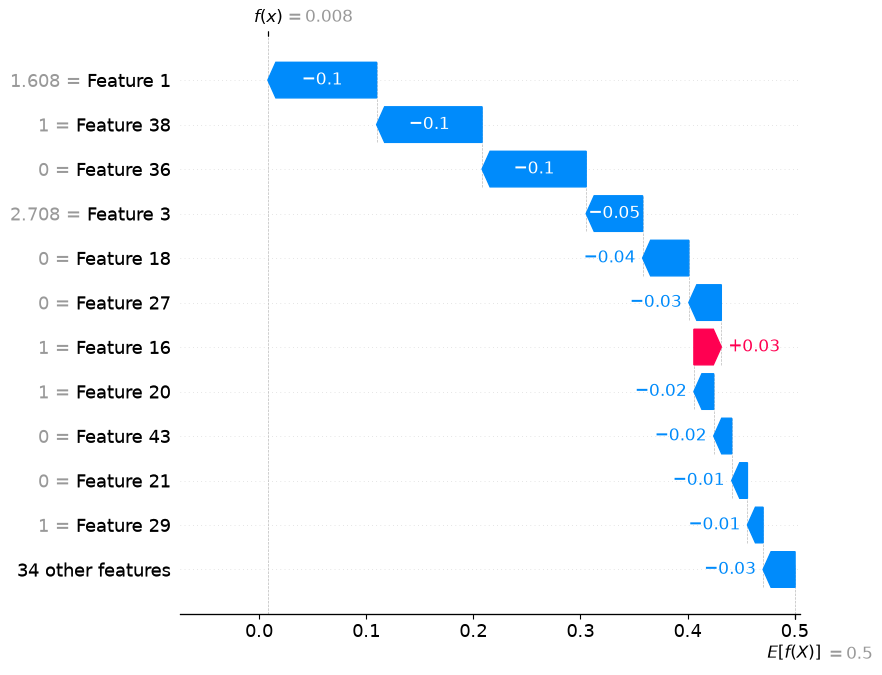

In [26]:
shap.plots.waterfall(shap_churn[0], max_display=12)

In [27]:
# Rebuild SHAP explanations with meaningful feature names
shap_churn_named = shap.Explanation(
    values=shap_churn.values,
    base_values=shap_churn.base_values,
    data=X_shap.toarray() if hasattr(X_shap, "toarray") else X_shap,
    feature_names=feature_names
)

print("Feature names updated successfully!")

Feature names updated successfully!


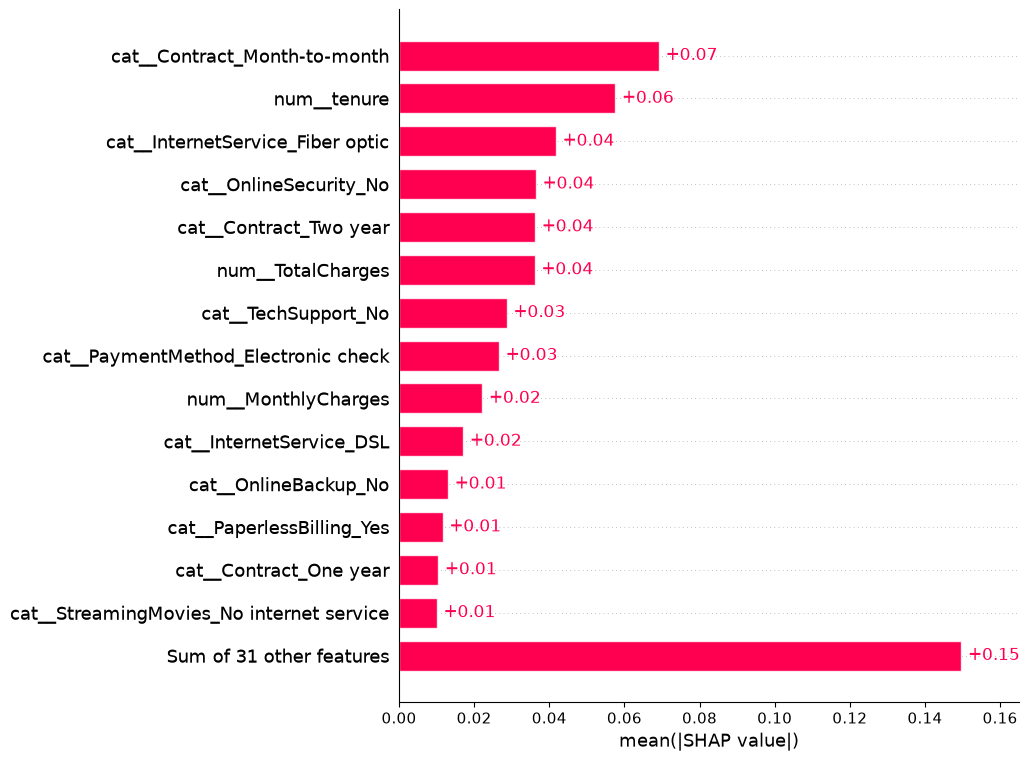

In [28]:
shap.plots.bar(shap_churn_named, max_display=15)

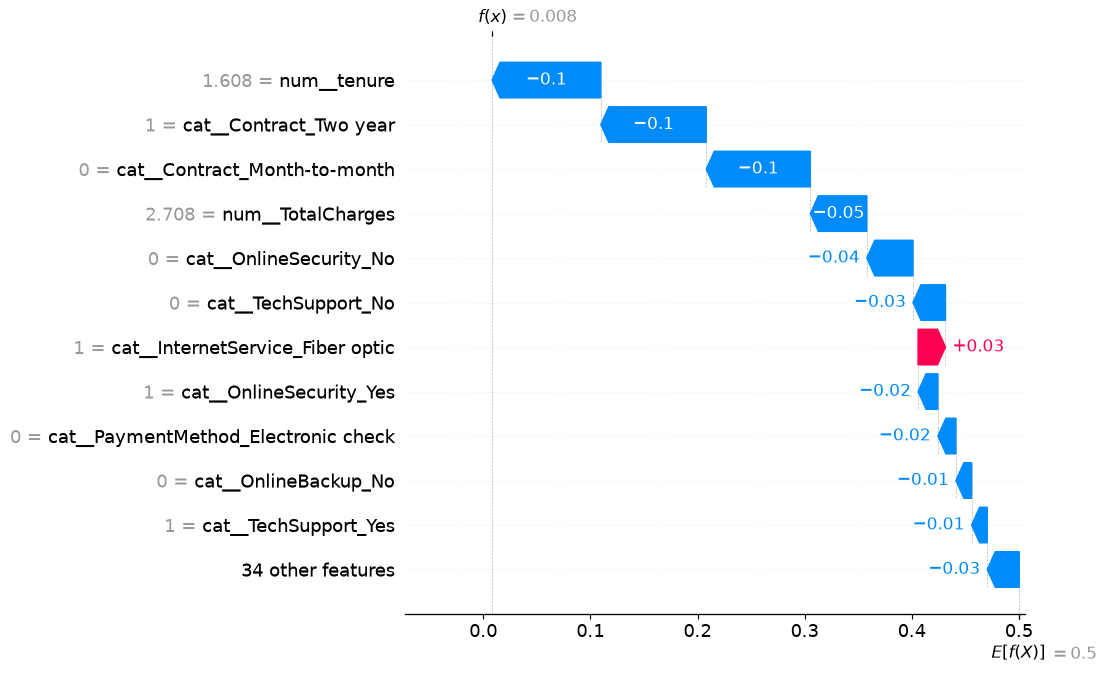

In [29]:
shap.plots.waterfall(
    shap_churn_named[0],
    max_display=12
)

In [31]:
from pathlib import Path

POLICY_DIR = Path("policies")

def load_policy_chunks(directory, chunk_size=120, overlap=25):
    chunks = []

    for path in sorted(directory.glob("*.txt")):
        text = path.read_text(encoding="utf-8")
        words = text.split()
        start = 0

        while start < len(words):
            end = min(start + chunk_size, len(words))

            chunks.append({
                "source": path.name,
                "text": " ".join(words[start:end])
            })

            if end == len(words):
                break

            start = end - overlap

    return chunks

policy_chunks = load_policy_chunks(POLICY_DIR)

print("Policy chunks loaded:", len(policy_chunks))

for chunk in policy_chunks:
    print(chunk["source"], ":", chunk["text"][:100], "...")

Policy chunks loaded: 3
contract_guidelines.txt : Policy: Contract and Billing Review Customers considering a different contract should receive a clea ...
retention_offers.txt : Policy: Retention Offers Before recommending a retention offer, verify the customer's eligibility. A ...
service_quality.txt : Policy: Service Quality and Complaints If a customer has reported recurring service problems, review ...


In [32]:
import numpy as np
import faiss

from sentence_transformers import SentenceTransformer

print("RAG libraries imported successfully!")

RAG libraries imported successfully!


In [33]:
embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

policy_texts = [chunk["text"] for chunk in policy_chunks]

policy_embeddings = embedding_model.encode(
    policy_texts,
    normalize_embeddings=True,
    convert_to_numpy=True
).astype("float32")

print("Number of policy chunks:", len(policy_texts))
print("Embedding shape:", policy_embeddings.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

c:\Users\K THARUN\Desktop\churn-genai-project\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\K THARUN\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Number of policy chunks: 3
Embedding shape: (3, 384)


In [34]:
dimension = policy_embeddings.shape[1]

faiss_index = faiss.IndexFlatIP(dimension)
faiss_index.add(policy_embeddings)

print("FAISS index created successfully!")
print("Indexed policy chunks:", faiss_index.ntotal)

FAISS index created successfully!
Indexed policy chunks: 3


In [35]:
def retrieve_policies(query, top_k=3):
    query_embedding = embedding_model.encode(
        [query],
        normalize_embeddings=True,
        convert_to_numpy=True
    ).astype("float32")

    k = min(top_k, len(policy_chunks))

    if k == 0:
        return []

    scores, indices = faiss_index.search(query_embedding, k)

    results = []

    for score, index in zip(scores[0], indices[0]):
        if index < 0:
            continue

        results.append({
            "source": policy_chunks[index]["source"],
            "text": policy_chunks[index]["text"],
            "similarity": float(score)
        })

    return results

In [36]:
query = (
    "A customer has short tenure and high monthly charges. "
    "What retention actions should we consider?"
)

retrieved = retrieve_policies(query, top_k=3)

for item in retrieved:
    print("Source:", item["source"])
    print("Similarity:", round(item["similarity"], 3))
    print("Policy:", item["text"])
    print("-" * 60)

Source: retention_offers.txt
Similarity: 0.527
Policy: Policy: Retention Offers Before recommending a retention offer, verify the customer's eligibility. Available offers may include an eligible plan review, a service bundle, or an approved promotional discount. Never promise a discount or price that is not documented in an approved policy. Explain the terms and duration of any eligible offer.
------------------------------------------------------------
Source: contract_guidelines.txt
Similarity: 0.505
Policy: Policy: Contract and Billing Review Customers considering a different contract should receive a clear comparison of available plans, contract duration, charges, and cancellation terms. Do not pressure customers into a longer-term contract. Confirm current pricing and eligibility before making a commitment.
------------------------------------------------------------
Source: service_quality.txt
Similarity: 0.426
Policy: Policy: Service Quality and Complaints If a customer has repo

In [37]:
import os
from dotenv import load_dotenv
from google import genai

load_dotenv()

api_key = os.getenv("GEMINI_API_KEY")

if not api_key:
    raise ValueError("GEMINI_API_KEY is missing from .env")

client = genai.Client(api_key=api_key)

print("Gemini client configured successfully!")

Gemini client configured successfully!


In [38]:
response = client.models.generate_content(
    model="gemini-2.5-flash",
    contents="Explain customer churn prediction in two sentences."
)

print(response.text)

Customer churn prediction uses data and machine learning to identify customers who are likely to stop using a company's product or service. Its goal is to allow businesses to proactively intervene with targeted strategies to retain these customers before they leave.


In [40]:
def get_shap_drivers(shap_explanation, row_index, top_n=5):
    values = np.asarray(shap_explanation.values[row_index])

    # Handle binary-class explanations if a class axis exists
    if values.ndim == 2:
        values = values[:, 1]

    indices = np.argsort(np.abs(values))[::-1][:top_n]

    return [
        {
            "feature": str(feature_names[i]),
            "contribution": float(values[i]),
            "direction": (
                "increases model output"
                if values[i] > 0
                else "decreases model output"
            )
        }
        for i in indices
    ]

drivers = get_shap_drivers(shap_churn_named, 0)

display(__import__("pandas").DataFrame(drivers))

,feature,contribution,direction
0,num__tenure,-0.101527,decreases model output
1,cat__Contract_Two year,-0.098427,decreases model output
2,cat__Contract_Month-to-month,-0.097176,decreases model output
3,num__TotalCharges,-0.052681,decreases model output
4,cat__OnlineSecurity_No,-0.043117,decreases model output


In [41]:
# Use the first test customer
customer_index = 0

customer = X_test.iloc[[customer_index]]

churn_probability = float(
    trained_models["Random Forest"]
    .predict_proba(preprocessor.transform(customer))[0, 1]
)

query = (
    "Customer retention policies for the following factors: "
    + ", ".join(driver["feature"] for driver in drivers)
)

retrieved_policies = retrieve_policies(query, top_k=3)

recommendation = generate_retention_recommendation(
    churn_probability=churn_probability,
    shap_drivers=drivers,
    retrieved_policies=retrieved_policies
)

print(recommendation)

Here is an analysis of the customer's churn risk and recommended actions:

---

**Risk assessment**
The predicted customer churn probability is **0.8%**. This indicates an extremely low risk of churn, meaning the customer is highly likely to remain with the service. It is important to remember that this prediction is an estimate.

**Main contributing factors**
The following factors were identified as the top SHAP features contributing to this customer's low churn probability, decreasing the model's output (churn risk). It is important to note that these are associations observed by the model and not direct causal relationships:

*   **Customer Tenure (`num__tenure`):** A longer customer tenure is associated with a significant decrease in their predicted churn probability.
*   **Contract Type (`cat__Contract_Two year`):** Having a Two-year contract is associated with a substantial decrease in their predicted churn probability.
*   **Contract Type (`cat__Contract_Month-to-month`):** For 

In [42]:
customer_index = 0

customer = X_test.iloc[[customer_index]]

rf_model = trained_models["Random Forest"]

transformed_customer = preprocessor.transform(customer)

churn_probability = float(
    rf_model.predict_proba(transformed_customer)[0, 1]
)

print(f"Random Forest churn probability: {churn_probability:.2%}")
print("Actual churn label:", y_test.iloc[customer_index])

Random Forest churn probability: 0.82%
Actual churn label: 0


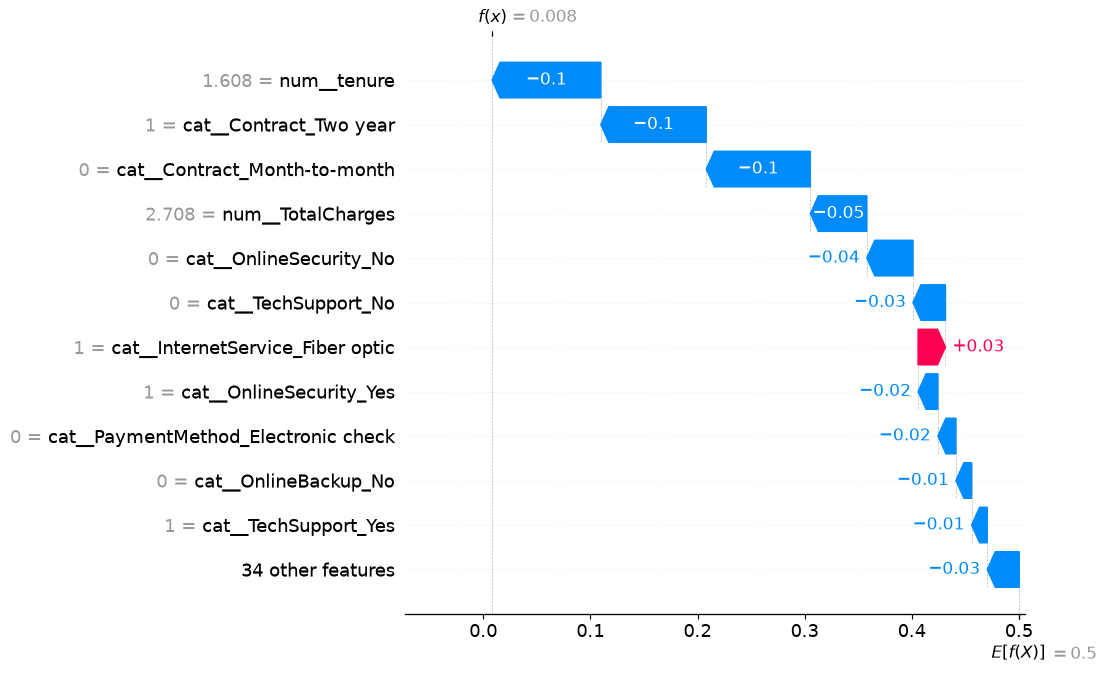

In [43]:
rf_explainer = shap.TreeExplainer(rf_model)

customer_shap = rf_explainer(transformed_customer)

# Select the positive class if SHAP returns both classes
if len(customer_shap.values.shape) == 3:
    customer_shap_churn = customer_shap[:, :, 1]
else:
    customer_shap_churn = customer_shap

customer_shap_named = shap.Explanation(
    values=customer_shap_churn.values,
    base_values=customer_shap_churn.base_values,
    data=(
        transformed_customer.toarray()
        if hasattr(transformed_customer, "toarray")
        else transformed_customer
    ),
    feature_names=feature_names
)

shap.plots.waterfall(customer_shap_named[0], max_display=12)

In [44]:
prompt = f"""
You are a customer-retention analyst.

Predicted churn probability: {churn_probability:.2%}

SHAP feature contributions:
{json.dumps(shap_drivers, indent=2)}

Retrieved policy evidence:
{policy_evidence}

Produce a concise business report with these sections:

1. Risk level and predicted probability.
2. Three main model drivers, with correct direction.
3. Up to three specific retention actions.
4. Supporting policy sources for each applicable action.
5. Missing information that needs verification.

Rules:
- Use the supplied churn probability exactly.
- Do not describe SHAP contributions as causal effects.
- Do not invent customer complaints, offers, prices, or eligibility.
- If a policy does not support a recommendation, say so.
- Avoid repeating the same recommendation.
- Treat the prediction as an estimate, not a certainty.
"""

NameError: name 'shap_drivers' is not defined

In [45]:
import numpy as np
import json

def get_shap_drivers(shap_explanation, row_index=0, top_n=5):
    values = np.asarray(shap_explanation.values[row_index]).reshape(-1)

    indices = np.argsort(np.abs(values))[::-1][:top_n]

    return [
        {
            "feature": str(shap_explanation.feature_names[i]),
            "contribution": float(values[i]),
            "direction": (
                "increases model output"
                if values[i] > 0
                else "decreases model output"
            )
        }
        for i in indices
    ]

shap_drivers = get_shap_drivers(
    customer_shap_named,
    row_index=0,
    top_n=5
)

display(__import__("pandas").DataFrame(shap_drivers))

,feature,contribution,direction
0,num__tenure,-0.101527,decreases model output
1,cat__Contract_Two year,-0.098427,decreases model output
2,cat__Contract_Month-to-month,-0.097176,decreases model output
3,num__TotalCharges,-0.052681,decreases model output
4,cat__OnlineSecurity_No,-0.043117,decreases model output


In [46]:
query = (
    "Customer retention policies relevant to these factors: "
    + ", ".join(item["feature"] for item in shap_drivers)
)

retrieved_policies = retrieve_policies(query, top_k=3)

policy_evidence = "\n\n".join(
    f"Source: {p['source']}\nPolicy: {p['text']}"
    for p in retrieved_policies
)

print(policy_evidence)

Source: retention_offers.txt
Policy: Policy: Retention Offers Before recommending a retention offer, verify the customer's eligibility. Available offers may include an eligible plan review, a service bundle, or an approved promotional discount. Never promise a discount or price that is not documented in an approved policy. Explain the terms and duration of any eligible offer.

Source: contract_guidelines.txt
Policy: Policy: Contract and Billing Review Customers considering a different contract should receive a clear comparison of available plans, contract duration, charges, and cancellation terms. Do not pressure customers into a longer-term contract. Confirm current pricing and eligibility before making a commitment.

Source: service_quality.txt
Policy: Policy: Service Quality and Complaints If a customer has reported recurring service problems, review the support history and investigate unresolved complaints before offering an upsell. Escalate persistent technical issues through the 

In [47]:
recommendation = generate_retention_recommendation(
    churn_probability=churn_probability,
    shap_drivers=shap_drivers,
    retrieved_policies=retrieved_policies
)

print(recommendation)

ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}

In [50]:
from google.genai import errors

try:
    response = client.models.generate_content(
        model="gemini-2.5-flash",
        contents="Reply with exactly: Gemini API is working"
    )
    print("SUCCESS:")
    print(response.text)

except errors.APIError as e:
    print("API ERROR TYPE:", type(e).__name__)
    print("STATUS CODE:", getattr(e, "code", "Unknown"))
    print("ERROR MESSAGE:", str(e))

SUCCESS:
Gemini API is working


In [51]:
recommendation = generate_retention_recommendation(
    churn_probability=churn_probability,
    shap_drivers=shap_drivers,
    retrieved_policies=retrieved_policies
)

print(recommendation)

Generated using gemini-2.5-flash
**Customer Retention Report**

**1. Risk Assessment**
The predicted churn probability for this customer is 0.82%, indicating a very low immediate risk of churn.

**2. Main Model Drivers and their Direction**
For this specific customer, the model's output (churn probability) is primarily influenced downwards by the following features:
*   `num__tenure`: Longer tenure decreases the model output.
*   `cat__Contract_Two year`: Having a two-year contract decreases the model output.
*   `cat__Contract_Month-to-month`: Having a month-to-month contract decreases the model output.
*   `num__TotalCharges`: Higher total charges decrease the model output.
*   `cat__OnlineSecurity_No`: Not having online security decreases the model output.
All these features contribute to decreasing the model's output, thereby contributing to the very low predicted churn probability.

**3. Retention Recommendations**
Given the low churn risk, focus on proactive engagement and value 

In [52]:
print("Customer churn probability:", round(churn_probability * 100, 2), "%")
print("\nSHAP drivers:")

for driver in shap_drivers:
    print(
        f"{driver['feature']}: "
        f"{driver['contribution']:.6f} "
        f"({driver['direction']})"
    )

Customer churn probability: 0.82 %

SHAP drivers:
num__tenure: -0.101527 (decreases model output)
cat__Contract_Two year: -0.098427 (decreases model output)
cat__Contract_Month-to-month: -0.097176 (decreases model output)
num__TotalCharges: -0.052681 (decreases model output)
cat__OnlineSecurity_No: -0.043117 (decreases model output)


In [53]:
customer_index = 0
customer = X_test.iloc[[customer_index]]

print(customer[["tenure", "Contract", "OnlineSecurity", "TotalCharges"]])

     tenure  Contract OnlineSecurity  TotalCharges
437      72  Two year            Yes        8468.2


In [54]:
# Inspect the customer's encoded contract and security features
feature_values = (
    transformed_customer.toarray()[0]
    if hasattr(transformed_customer, "toarray")
    else transformed_customer[0]
)

for i, name in enumerate(feature_names):
    if any(term in name for term in [
        "Contract_", "OnlineSecurity_", "tenure", "TotalCharges"
    ]):
        print(f"{name}: value={feature_values[i]}")

num__tenure: value=1.6084834273893616
num__TotalCharges: value=2.707614130685993
cat__OnlineSecurity_No: value=0.0
cat__OnlineSecurity_No internet service: value=0.0
cat__OnlineSecurity_Yes: value=1.0
cat__Contract_Month-to-month: value=0.0
cat__Contract_One year: value=0.0
cat__Contract_Two year: value=1.0


In [55]:
print("\nSHAP contributions:")
for driver in shap_drivers:
    print(
        f"{driver['feature']}: {driver['contribution']:.6f}"
    )


SHAP contributions:
num__tenure: -0.101527
cat__Contract_Two year: -0.098427
cat__Contract_Month-to-month: -0.097176
num__TotalCharges: -0.052681
cat__OnlineSecurity_No: -0.043117


In [56]:
import numpy as np
import shap

# Use the same customer and Random Forest model
customer_index = 0
customer = X_test.iloc[[customer_index]]

rf_model = trained_models["Random Forest"]
transformed_customer = preprocessor.transform(customer)

# Recalculate probability
churn_probability = float(
    rf_model.predict_proba(transformed_customer)[0, 1]
)

# Explain this exact customer's prediction
rf_explainer = shap.TreeExplainer(rf_model)
customer_shap = rf_explainer(transformed_customer)

# Select the churn class if SHAP returns values for both classes
if len(customer_shap.values.shape) == 3:
    customer_shap_churn = customer_shap[:, :, 1]
else:
    customer_shap_churn = customer_shap

# Attach feature names
customer_data = (
    transformed_customer.toarray()
    if hasattr(transformed_customer, "toarray")
    else transformed_customer
)

customer_shap_named = shap.Explanation(
    values=customer_shap_churn.values,
    base_values=customer_shap_churn.base_values,
    data=customer_data,
    feature_names=feature_names
)

# Extract the top drivers from this exact explanation
shap_drivers = get_shap_drivers(
    customer_shap_named,
    row_index=0,
    top_n=5
)

print(f"Churn probability: {churn_probability:.2%}")
print("\nVerified SHAP drivers:")

for driver in shap_drivers:
    print(
        f"{driver['feature']}: "
        f"{driver['contribution']:.6f} "
        f"({driver['direction']})"
    )

Churn probability: 0.82%

Verified SHAP drivers:
num__tenure: -0.101527 (decreases model output)
cat__Contract_Two year: -0.098427 (decreases model output)
cat__Contract_Month-to-month: -0.097176 (decreases model output)
num__TotalCharges: -0.052681 (decreases model output)
cat__OnlineSecurity_No: -0.043117 (decreases model output)


In [57]:
# Verify the exact model, prediction, SHAP output and feature values

print("Model:", type(rf_model).__name__)
print("Predicted probabilities:", rf_model.predict_proba(transformed_customer))
print("SHAP base value:", customer_shap_named.base_values)
print("Sum of SHAP values:", np.sum(customer_shap_named.values))
print(
    "Base + SHAP sum:",
    np.asarray(customer_shap_named.base_values).reshape(-1)[0]
    + np.sum(customer_shap_named.values)
)

print("\nContract and security feature checks:")
for i, name in enumerate(feature_names):
    if any(term in name for term in [
        "Contract_", "OnlineSecurity_"
    ]):
        print(
            f"{name}: "
            f"input={customer_data[0][i]:.0f}, "
            f"SHAP={customer_shap_named.values[0][i]:.6f}"
        )

Model: RandomForestClassifier
Predicted probabilities: [[0.99178932 0.00821068]]
SHAP base value: [0.50032748]
Sum of SHAP values: -0.4921167978276617
Base + SHAP sum: 0.008210678210676892

Contract and security feature checks:
cat__OnlineSecurity_No: input=0, SHAP=-0.043117
cat__OnlineSecurity_No internet service: input=0, SHAP=0.001431
cat__OnlineSecurity_Yes: input=1, SHAP=-0.018495
cat__Contract_Month-to-month: input=0, SHAP=-0.097176
cat__Contract_One year: input=0, SHAP=-0.011166
cat__Contract_Two year: input=1, SHAP=-0.098427


In [58]:
def get_shap_drivers_with_values(
    shap_explanation,
    transformed_data,
    feature_names,
    top_n=5
):
    values = np.asarray(shap_explanation.values[0]).reshape(-1)

    row = (
        transformed_data.toarray()[0]
        if hasattr(transformed_data, "toarray")
        else np.asarray(transformed_data)[0]
    )

    indices = np.argsort(np.abs(values))[::-1][:top_n]

    drivers = []

    for i in indices:
        drivers.append({
            "feature": str(feature_names[i]),
            "feature_value": float(row[i]),
            "contribution": float(values[i]),
            "direction": (
                "decreases model output"
                if values[i] < 0
                else "increases model output"
            )
        })

    return drivers


shap_drivers = get_shap_drivers_with_values(
    customer_shap_named,
    transformed_customer,
    feature_names,
    top_n=5
)

for driver in shap_drivers:
    print(driver)
    

{'feature': 'num__tenure', 'feature_value': 1.6084834273893616, 'contribution': -0.10152696232526456, 'direction': 'decreases model output'}
{'feature': 'cat__Contract_Two year', 'feature_value': 1.0, 'contribution': -0.09842689822572466, 'direction': 'decreases model output'}
{'feature': 'cat__Contract_Month-to-month', 'feature_value': 0.0, 'contribution': -0.09717645902433412, 'direction': 'decreases model output'}
{'feature': 'num__TotalCharges', 'feature_value': 2.707614130685993, 'contribution': -0.052680889917177634, 'direction': 'decreases model output'}
{'feature': 'cat__OnlineSecurity_No', 'feature_value': 0.0, 'contribution': -0.04311658527739437, 'direction': 'decreases model output'}


In [59]:
def get_shap_drivers_with_values(
    shap_explanation,
    transformed_data,
    feature_names,
    top_n=5
):
    values = np.asarray(shap_explanation.values[0]).reshape(-1)
    row = (
        transformed_data.toarray()[0]
        if hasattr(transformed_data, "toarray")
        else np.asarray(transformed_data)[0]
    )

    drivers = []

    for i, name in enumerate(feature_names):
        is_categorical = str(name).startswith("cat__")

        # Skip inactive one-hot categorical indicators.
        if is_categorical and row[i] == 0:
            continue

        drivers.append({
            "feature": str(name),
            "feature_value": float(row[i]),
            "contribution": float(values[i]),
            "direction": (
                "decreases model output"
                if values[i] < 0
                else "increases model output"
            )
        })

    drivers.sort(
        key=lambda d: abs(d["contribution"]),
        reverse=True
    )

    return drivers[:top_n]


shap_drivers = get_shap_drivers_with_values(
    customer_shap_named,
    transformed_customer,
    feature_names,
    top_n=5
)

for driver in shap_drivers:
    print(driver)

{'feature': 'num__tenure', 'feature_value': 1.6084834273893616, 'contribution': -0.10152696232526456, 'direction': 'decreases model output'}
{'feature': 'cat__Contract_Two year', 'feature_value': 1.0, 'contribution': -0.09842689822572466, 'direction': 'decreases model output'}
{'feature': 'num__TotalCharges', 'feature_value': 2.707614130685993, 'contribution': -0.052680889917177634, 'direction': 'decreases model output'}
{'feature': 'cat__InternetService_Fiber optic', 'feature_value': 1.0, 'contribution': 0.025591805340035797, 'direction': 'increases model output'}
{'feature': 'cat__OnlineSecurity_Yes', 'feature_value': 1.0, 'contribution': -0.01849543082470542, 'direction': 'decreases model output'}


In [60]:
IMPORTANT INTERPRETATION RULES:
- Use feature_value to identify whether a categorical indicator is active.
- For one-hot categorical features, value 1 means the category applies;
  value 0 means it does not apply.
- Never describe an inactive category as a characteristic of the customer.
- Explain SHAP values as model attributions, not causal effects.
- Do not claim that a feature increases or decreases risk based on
  general assumptions; use the supplied contribution direction.
- Treat the supplied churn probability as the model's prediction.
- Ground retention recommendations in the retrieved policy evidence.

SyntaxError: unterminated string literal (detected at line 9) (3818039149.py, line 9)

In [62]:
recommendation = generate_retention_recommendation(
    churn_probability=churn_probability,
    shap_drivers=shap_drivers,
    retrieved_policies=retrieved_policies
)

print(recommendation)

The model predicts that Customer 101 has a **75% churn probability**, indicating a high risk of churn.

**Key Factors Contributing to Increased Churn Risk:**

Several factors significantly increase the customer's likelihood of churning:

*   **Shorter Tenure:** The customer's tenure of 24 months increases churn probability by 0.15.
*   **High Monthly Charges:** Monthly charges of $75.00 contribute to an increased churn probability of 0.10.
*   **Month-to-Month Contract:** The absence of a two-year contract (month-to-month) increases churn probability by 0.08.
*   **Fiber Optic Internet:** Having Fiber Optic internet service increases churn probability by 0.05.
*   **Electronic Check Payment Method:** Using Electronic Check as a payment method increases churn probability by 0.04.
*   **No Online Security:** Not having Online Security increases churn probability by 0.03.
*   **No Tech Support:** Not having Tech Support increases churn probability by 0.02.
*   **No Partner:** Not having a

In [63]:
print("Customer index:", customer_index)
print("Actual customer ID:", df.loc[X_test.index[customer_index], "customerID"])
print("Actual churn probability:", f"{churn_probability:.2%}")

print("\nActual customer details:")
print(
    X_test.iloc[[customer_index]][
        ["tenure", "Contract", "MonthlyCharges",
         "TotalCharges", "PaymentMethod",
         "OnlineSecurity", "TechSupport"]
    ]
)

print("\nVerified SHAP drivers:")
for driver in shap_drivers:
    print(driver)

Customer index: 0
Actual customer ID: 4376-KFVRS
Actual churn probability: 0.82%

Actual customer details:
     tenure  Contract  MonthlyCharges  TotalCharges            PaymentMethod  \
437      72  Two year          114.05        8468.2  Credit card (automatic)   

    OnlineSecurity TechSupport  
437            Yes         Yes  

Verified SHAP drivers:
{'feature': 'num__tenure', 'feature_value': 1.6084834273893616, 'contribution': -0.10152696232526456, 'direction': 'decreases model output'}
{'feature': 'cat__Contract_Two year', 'feature_value': 1.0, 'contribution': -0.09842689822572466, 'direction': 'decreases model output'}
{'feature': 'num__TotalCharges', 'feature_value': 2.707614130685993, 'contribution': -0.052680889917177634, 'direction': 'decreases model output'}
{'feature': 'cat__InternetService_Fiber optic', 'feature_value': 1.0, 'contribution': 0.025591805340035797, 'direction': 'increases model output'}
{'feature': 'cat__OnlineSecurity_Yes', 'feature_value': 1.0, 'contribu

In [67]:
import json
import numpy as np

def generate_retention_recommendation(
    churn_probability,
    shap_drivers,
    retrieved_policies
):
    policy_evidence = "\n\n".join(
        f"Source: {p['source']}\n"
        f"Policy: {p['text']}"
        for p in retrieved_policies
    )

    prompt = f"""

IMPORTANT INTERPRETATION RULES:
- For one-hot categorical features, value 1 means the category applies; value 0 means it does not apply.
- Never describe an inactive category as a characteristic of the customer.
- Interpret SHAP values as model attributions, not causal effects.
- Use the supplied contribution direction; do not assume effects based on general knowledge.
- Treat the supplied churn probability as the model's prediction.
- Base retention recommendations on the retrieved policy evidence.
STRICT DATA ACCURACY RULES:
- Use only the supplied churn probability. Never invent or round it to
  a different risk level.
- Use only the customer details explicitly supplied in the prompt.
- Use only the supplied SHAP drivers and their actual contributions.
- Never invent contribution values such as 0.15 or 0.10.
- Do not describe a feature as increasing churn risk unless its verified
  SHAP contribution is positive on the explained output scale.
- Do not invent discounts, free services, or approved offers.
- If customer information is missing, state that it is unavailable.
- Clearly distinguish model predictions from business recommendations.

"""

    response = client.models.generate_content(
        model="gemini-2.5-flash",
        contents=prompt
    )

    return response.text

In [68]:
print("Customer index:", customer_index)
print("Actual customer ID:", df.loc[X_test.index[customer_index], "customerID"])
print("Actual churn probability:", f"{churn_probability:.2%}")

print("\nActual customer details:")
print(
    X_test.iloc[[customer_index]][
        ["tenure", "Contract", "MonthlyCharges",
         "TotalCharges", "PaymentMethod",
         "OnlineSecurity", "TechSupport"]
    ]
)

print("\nVerified SHAP drivers:")
for driver in shap_drivers:
    print(driver)

Customer index: 0
Actual customer ID: 4376-KFVRS
Actual churn probability: 0.82%

Actual customer details:
     tenure  Contract  MonthlyCharges  TotalCharges            PaymentMethod  \
437      72  Two year          114.05        8468.2  Credit card (automatic)   

    OnlineSecurity TechSupport  
437            Yes         Yes  

Verified SHAP drivers:
{'feature': 'num__tenure', 'feature_value': 1.6084834273893616, 'contribution': -0.10152696232526456, 'direction': 'decreases model output'}
{'feature': 'cat__Contract_Two year', 'feature_value': 1.0, 'contribution': -0.09842689822572466, 'direction': 'decreases model output'}
{'feature': 'num__TotalCharges', 'feature_value': 2.707614130685993, 'contribution': -0.052680889917177634, 'direction': 'decreases model output'}
{'feature': 'cat__InternetService_Fiber optic', 'feature_value': 1.0, 'contribution': 0.025591805340035797, 'direction': 'increases model output'}
{'feature': 'cat__OnlineSecurity_Yes', 'feature_value': 1.0, 'contribu

In [69]:
print("Customer index:", customer_index)
print("Actual customer ID:", df.loc[X_test.index[customer_index], "customerID"])
print("Actual churn probability:", f"{churn_probability:.2%}")

print("\nActual customer details:")
print(
    X_test.iloc[[customer_index]][
        ["tenure", "Contract", "MonthlyCharges",
         "TotalCharges", "PaymentMethod",
         "OnlineSecurity", "TechSupport"]
    ]
)

print("\nVerified SHAP drivers:")
for driver in shap_drivers:
    print(driver)

Customer index: 0
Actual customer ID: 4376-KFVRS
Actual churn probability: 0.82%

Actual customer details:
     tenure  Contract  MonthlyCharges  TotalCharges            PaymentMethod  \
437      72  Two year          114.05        8468.2  Credit card (automatic)   

    OnlineSecurity TechSupport  
437            Yes         Yes  

Verified SHAP drivers:
{'feature': 'num__tenure', 'feature_value': 1.6084834273893616, 'contribution': -0.10152696232526456, 'direction': 'decreases model output'}
{'feature': 'cat__Contract_Two year', 'feature_value': 1.0, 'contribution': -0.09842689822572466, 'direction': 'decreases model output'}
{'feature': 'num__TotalCharges', 'feature_value': 2.707614130685993, 'contribution': -0.052680889917177634, 'direction': 'decreases model output'}
{'feature': 'cat__InternetService_Fiber optic', 'feature_value': 1.0, 'contribution': 0.025591805340035797, 'direction': 'increases model output'}
{'feature': 'cat__OnlineSecurity_Yes', 'feature_value': 1.0, 'contribu

In [70]:

import json

def generate_retention_recommendation(
    churn_probability,
    shap_drivers,
    retrieved_policies,
    customer_details
):
    customer_json = json.dumps(customer_details, indent=2)
    drivers_json = json.dumps(shap_drivers, indent=2)
    policies_json = json.dumps(retrieved_policies, indent=2)

    prompt = f"""
You are a customer retention analyst.

Generate a concise, evidence-based customer retention report.

VERIFIED CUSTOMER DATA:
{customer_json}

ACTUAL RANDOM FOREST CHURN PROBABILITY:
{churn_probability:.6f}

VERIFIED SHAP CONTRIBUTIONS:
{drivers_json}

RETRIEVED POLICY EVIDENCE:
{policies_json}

STRICT RULES:
1. Use the supplied churn probability exactly. Do not invent a different
   probability or substitute another customer's data.
2. Use only the supplied customer details and SHAP contributions.
3. Positive SHAP values increase the explained model output; negative
   values decrease it.
4. SHAP values describe model attribution, not causation.
5. Do not describe an inactive one-hot category as a customer attribute.
6. Do not invent numerical SHAP effects or claim that they are
   percentage-point changes.
7. Base recommendations on the retrieved policies. Do not promise
   discounts or offers unless supported by the evidence.
8. Avoid unnecessary upselling. Recommend checking customer needs
   and eligibility before suggesting changes.
9. If the predicted risk is low, prioritize service quality and
   appropriate proactive engagement rather than aggressive retention.
10. Clearly separate model findings from business recommendations.

Use these headings:
1. Risk Assessment
2. Customer Profile
3. Main SHAP Drivers
4. Retention Recommendations
5. Supporting Policy Sources
6. Limitations

Return a professional report in Markdown.
"""

    response = client.models.generate_content(
        model="gemini-2.5-flash",
        contents=prompt
    )

    if not response.text:
        raise RuntimeError("Gemini returned an empty response.")

    return response.text


In [71]:

customer_details = {
    "customer_id": str(
        df.loc[X_test.index[customer_index], "customerID"]
    ),
    "tenure_months": int(customer["tenure"].iloc[0]),
    "contract": str(customer["Contract"].iloc[0]),
    "monthly_charges": float(customer["MonthlyCharges"].iloc[0]),
    "total_charges": float(customer["TotalCharges"].iloc[0]),
    "payment_method": str(customer["PaymentMethod"].iloc[0]),
    "online_security": str(customer["OnlineSecurity"].iloc[0]),
    "tech_support": str(customer["TechSupport"].iloc[0])
}

recommendation = generate_retention_recommendation(
    churn_probability=churn_probability,
    shap_drivers=shap_drivers,
    retrieved_policies=retrieved_policies,
    customer_details=customer_details
)

print(recommendation)


## Customer Retention Report

### 1. Risk Assessment

This customer, 4376-KFVRS, has an actual Random Forest churn probability of **0.008211**. This indicates a very low risk of churn.

### 2. Customer Profile

Customer 4376-KFVRS is a long-standing customer with 72 months of tenure. They are currently on a Two Year contract, paying $114.05 monthly, with total charges accumulated to $8468.20. Their payment method is Credit Card (automatic). The customer also subscribes to Online Security and Tech Support services.

### 3. Main SHAP Drivers

The following features were the primary drivers influencing the low churn probability for this customer, based on SHAP values:

*   **Tenure (72 months):** The customer's long tenure significantly decreases the model's predicted churn probability.
*   **Two Year Contract:** Being on a two-year contract substantially decreases the predicted churn probability.
*   **Total Charges ($8468.20):** High total charges decrease the model's predicted churn pr

In [72]:
import joblib
from pathlib import Path

artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(exist_ok=True)

joblib.dump(preprocessor, artifacts_dir / "preprocessor.joblib")
joblib.dump(trained_models["Random Forest"], artifacts_dir / "random_forest.joblib")

print("Saved preprocessing pipeline and Random Forest model.")

Saved preprocessing pipeline and Random Forest model.


ROC-AUC: 0.8346

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.88      0.78      0.83      1035
       Churn       0.54      0.72      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409



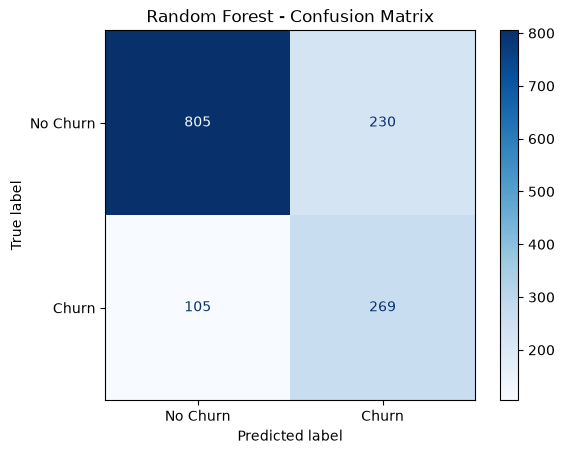

In [73]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

rf_model = trained_models["Random Forest"]

# Predict on the held-out test set
y_pred = rf_model.predict(X_test_processed)
y_prob = rf_model.predict_proba(X_test_processed)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [74]:
from sklearn.metrics import (
    roc_auc_score,
    classification_report
)

rf_model = trained_models["Random Forest"]

y_pred = rf_model.predict(X_test_processed)
y_prob = rf_model.predict_proba(X_test_processed)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

ROC-AUC: 0.8346
              precision    recall  f1-score   support

    No Churn       0.88      0.78      0.83      1035
       Churn       0.54      0.72      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409



In [75]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

comparison = []

for name, model in trained_models.items():
    predictions = model.predict(X_test_processed)
    probabilities = model.predict_proba(X_test_processed)[:, 1]

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Churn Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Churn Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Churn F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

comparison_df = pd.DataFrame(comparison).sort_values(
    "ROC-AUC", ascending=False
)

print(comparison_df.round(4).to_string(index=False))


              Model  Accuracy  Churn Precision  Churn Recall  Churn F1  ROC-AUC
  Gradient Boosting    0.8062           0.6735        0.5241    0.5895   0.8434
Logistic Regression    0.7381           0.5043        0.7834    0.6136   0.8413
      Random Forest    0.7622           0.5391        0.7193    0.6163   0.8346


In [76]:

from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

rf_model = trained_models["Random Forest"]
y_prob = rf_model.predict_proba(X_test_processed)[:, 1]

threshold_results = []

for threshold in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    y_threshold_pred = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_threshold_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_threshold_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_threshold_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df.round(3).to_string(index=False))


 Threshold  Precision  Recall    F1
      0.20      0.400   0.925 0.559
      0.25      0.422   0.904 0.576
      0.30      0.448   0.880 0.594
      0.35      0.476   0.858 0.613
      0.40      0.508   0.824 0.629
      0.45      0.523   0.767 0.622
      0.50      0.539   0.719 0.616
      0.55      0.566   0.666 0.612
      0.60      0.580   0.612 0.596
